In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Layer, Dense
from tensorflow.nn import relu
from tensorflow.keras.losses import BinaryCrossentropy
from sionna.phy.block import Block
from sionna.phy.utils import expand_to_rank, hard_decisions
import importlib
import pn_classes
importlib.reload(pn_classes)
from pn_classes import PhaseNoise, PN_Compensation, PTRS_Adder
import sionna as sn
import matplotlib.pyplot as plt
import os
import gc
from sionna.phy.mapping import Constellation, Demapper, SymbolLogits2LLRs, BinarySource
from sionna.phy.utils import split_dim

2026-11-25 20:37:25.071821: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1795631845.084135   31645 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1795631845.090169   31645 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1795631845.100284   31645 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1795631845.100301   31645 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1795631845.100303   31645 computation_placer.cc:177] computation placer alr

In [2]:

N_values = [16, 64, 256]

qam_constellations = {}

for N in N_values:

    num_bits_symbol = int(np.log2(N))

    constellation_qam = Constellation(
        "qam",
        num_bits_per_symbol=num_bits_symbol,
        normalize=True
    )

    points = constellation_qam.points.numpy()

    qam_constellations[N] = points

I0000 00:00:1795631857.045024   31645 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5606 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050, pci bus id: 0000:01:00.0, compute capability: 8.6


In [3]:

class Demapper_trainable(Demapper):
    def __init__(self,
                 demapping_method,
                 constellation_type=None,
                 num_bits_per_symbol=None,
                 constellation=None,
                 hard_out=False,
                 precision=None,
                 **kwargs):
        super().__init__(demapping_method=demapping_method, constellation=constellation, precision=precision, **kwargs)

        # Create constellation object
        self._constellation = Constellation.check_or_create(
            constellation_type=constellation_type,
            num_bits_per_symbol=num_bits_per_symbol,
            constellation=constellation,
            precision=precision)

        num_bits_per_symbol = self._constellation.num_bits_per_symbol

        self._logits2llrs = SymbolLogits2LLRs(demapping_method,
                                              num_bits_per_symbol,
                                              hard_out=hard_out,
                                              precision=precision,
                                              **kwargs)

        self._no_threshold = tf.cast(np.finfo(self.rdtype.as_numpy_dtype).tiny,
                                     self.rdtype)

    def call(self, y, no, points, prior=None):
        # Compute squared distances from y to all points
        # shape [...,n,num_points]
        squared_dist = tf.pow(tf.abs(tf.expand_dims(y, axis=-1) - points), 2)

        # Add a dummy dimension for broadcasting. This is not needed when no
        # is a scalar, but also does not do any harm.
        no = tf.expand_dims(no, axis=-1)
        # Deal with zero or very small values.
        no = tf.math.maximum(no, self._no_threshold)

        # Compute exponents
        exponents = -squared_dist / no
        llr = self._logits2llrs(exponents, prior)

        # Reshape LLRs to [...,n*num_bits_per_symbol]
        out_shape = tf.concat([tf.shape(y)[:-1],
                               [y.shape[-1] * \
                                self.constellation.num_bits_per_symbol]], 0)

        llr_reshaped = tf.reshape(llr, out_shape)

        return llr_reshaped


def normalize_constellation(points, probabilities):
    # Compute the power of the constellation
    power = np.sum(probabilities * np.abs(points) ** 2)
    # Normalize the constellation points
    normalized_points = points / np.sqrt(power)
    return normalized_points


def plot_constellation_wlabels(points, probabilities, plot_title):
    points = np.asarray(points)
    probabilities = np.asarray(probabilities).flatten()

    # Scale marker sizes for visibility
    marker_sizes = 300 * probabilities / max(probabilities)

    plt.figure(figsize=(8, 8))
    plt.scatter(points.real, points.imag, s=marker_sizes, alpha=0.7, c='b', edgecolors='k')

    # Annotate with 6-bit binary labels
    for i, pt in enumerate(points):
        label = format(i, '06b')  # 6-bit binary string
        plt.text(pt.real + 0.05, pt.imag + 0.05, label, fontsize=9, ha='left', va='bottom', color='darkred')

    # Add grid and formatting
    plt.axhline(0, color='gray', linewidth=0.5, linestyle='--')
    plt.axvline(0, color='gray', linewidth=0.5, linestyle='--')
    plt.grid(True, linestyle=':')
    plt.xlabel("In-phase")
    plt.ylabel("Quadrature")
    plt.title(plot_title)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.tight_layout()
    # plt.show()


class Mapper_trainable(Layer):
    def __init__(self, num_bits_per_symbol, constellation, **kwargs):
        super(Mapper_trainable, self).__init__(**kwargs)
        self.num_bits_per_symbol = num_bits_per_symbol
        self._bit_positions = tf.cast(tf.range(num_bits_per_symbol-1, -1, -1), dtype=tf.int32)

        self.constellation_real_init = constellation.real
        self.constellation_imag_init = constellation.imag

    def build(self, input_shape):
        self.constellation_real = self.add_weight(
            name="constellation_real",
            shape=self.constellation_real_init.shape,
            initializer=tf.constant_initializer(self.constellation_real_init),
            trainable=True
        )
        self.constellation_imag = self.add_weight(
            name="constellation_imag",
            shape=self.constellation_imag_init.shape,
            initializer=tf.constant_initializer(self.constellation_imag_init),
            trainable=True
        )


    def call(self, bits):

        C_points = tf.complex(self.constellation_real, self.constellation_imag)
        norm_C_points = C_points / tf.complex(tf.sqrt(tf.reduce_mean(tf.square(tf.abs(C_points)))),0.0)

         # Convert to int32
        bits = tf.cast(bits, dtype=tf.int32)

        # Reshape last dimensions to the desired format
        n1 = int(bits.shape[-1]/self.num_bits_per_symbol)
        new_shape = [n1 , self.num_bits_per_symbol]
        bits = split_dim(bits, new_shape, axis=tf.rank(bits)-1)

        # Use bitwise left shift to compute powers of two
        shifted_bits = tf.bitwise.left_shift(bits, self._bit_positions)

        # Compute the integer representation using bitwise operations
        int_rep = tf.reduce_sum(shifted_bits, axis=-1)

        # Map integers to constellation symbols
        x = tf.gather(norm_C_points, int_rep)
        return x, norm_C_points

In [4]:
class E2E_GCS_PAPR_PN(Model):
    def __init__(self,fc, N, constellation, device, constellation_orig, use_upsampling_filtering, batch_size, papr_batch_size, block_size):
        super().__init__()
        print('device', device)

        # self.sampling = SamplingMechanism_P0_trainable_parameter(N, tau, device, constellation)
        # self.sampling = Sampling_sym_sub_constellation(N, parity_k, tau, device, constellation, use_uniform)
        # self.modulator = Modulator()
        self.channel = sn.phy.channel.AWGN()
        self.demodulator_test = Demapper_trainable("app", constellation=constellation_orig)
        self.loss_fn = BinaryCrossentropy(from_logits=True, reduction=None, axis=0)
        self.N = N
        self.bits_per_symbol = int(np.log2(self.N))
        # self.bit_labels = tf.convert_to_tensor(np.array([[int(b) for b in format(i, f'0{self.bits_per_symbol}b')] for i in range(self.N)]),tf.float32)

        self.upsampler = sn.phy.signal.Upsampling(samples_per_symbol=4)
        self.tx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                         samples_per_symbol=4,
                                                         span_in_symbols=32)
        self.rx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                         samples_per_symbol=4,
                                                         span_in_symbols=32)
        self.downsampler = sn.phy.signal.Downsampling(samples_per_symbol=4,
                                                      offset = self.rx_filter.length - 1,
                                                 num_symbols=tf.cast(block_size+128, tf.int32))
        self.use_upsampling_filtering = use_upsampling_filtering

        self.mapper = Mapper_trainable(self.bits_per_symbol, constellation)
        self.binary_source = BinarySource()
        self.batch_size = batch_size
        self.papr_batch_size = papr_batch_size
        self.block_size = block_size

        num_ptrs_blocks = 32
        symbols_per_ptrs_block = 4
        block_size_ptrs = block_size+128
        bandwidth = 100e6
        # fc = 220e9
        samples = 4*(block_size_ptrs+32)

        path_to_mat = "../PreloadedMats/ptrs_CAZAC_4_32.mat"
        self.ptrs_adder = PTRS_Adder(path_to_mat, num_ptrs_blocks, symbols_per_ptrs_block, block_size_ptrs, batch_size)
        self.pn_compensate = PN_Compensation(self.ptrs_adder.ptrs_indices, self.ptrs_adder.data_indices, block_size_ptrs, self.ptrs_adder.pilots, batch_size)
        self.pn_tx = PhaseNoise(model_type='measured1', bandwidth=bandwidth, fc=fc, n_samples=samples)
        # self.pn_rx = PhaseNoise(model_type='11', bandwidth=bandwidth, fc=fc, n_samples=samples)

        self.prior_values = tf.convert_to_tensor(np.zeros(self.bits_per_symbol), tf.float32)

    def call(self, ebno_db, No):

        bit_input = self.binary_source([self.batch_size, self.block_size * self.bits_per_symbol])
        x_mod, norm_C_points = self.mapper(bit_input)
        ptrs_x_mod = self.ptrs_adder(x_mod)

        if self.use_upsampling_filtering:
            x_up = self.upsampler(ptrs_x_mod)
            x_tx_filt = self.tx_filter(x_up)
            pn_out, _, _ = self.pn_tx(x_tx_filt)
            y_channel = self.channel(pn_out, No)
            # y_channel_pn, _, _ = self.pn_rx(y_channel)
            y_rx_filt = self.rx_filter(y_channel)
            y = self.downsampler(y_rx_filt)
            _, y_data_vec = self.pn_compensate(y)

        else:
            # Transmit through the channel
            y = self.channel(x_mod, No)

        # Demodulate the received signal
        tf_points = tf.reshape(norm_C_points, (1, 1, self.N))
        logits = self.demodulator_test(y_data_vec, No, tf_points, self.prior_values)

        logits_reshaped = tf.reshape(logits, (self.batch_size, self.block_size, self.bits_per_symbol))
        bit_input_reshaped = tf.reshape(bit_input, (self.batch_size, self.block_size, self.bits_per_symbol))

        bce_matrix = tf.nn.sigmoid_cross_entropy_with_logits(labels=bit_input_reshaped, logits=logits_reshaped)
        loss_ordinary = tf.reduce_sum(tf.math.reduce_mean(bce_matrix, axis=[0,1]))

        # y_raw_data = tf.gather(y, self.ptrs_adder.data_indices, axis=1)

        loss = loss_ordinary - self.bits_per_symbol

        return loss, loss_ordinary#, y_raw_data, y_data_vec, bit_input_reshaped, logits_reshaped, x_mod

    @tf.function
    def compute_power_to_average_power_samples(self, papr_batch_size, papr_block_size):
        bits_power = self.binary_source([papr_batch_size, papr_block_size * self.bits_per_symbol])
        x_power,_ = self.mapper(bits_power)
        x_up_power = self.upsampler(x_power)
        x_tx_filt_power = self.tx_filter(x_up_power)  # 'same' for discarding the edges
        p_x = tf.square(tf.abs(x_tx_filt_power))
        power_samples = p_x / tf.reduce_mean(p_x)
        return power_samples


In [5]:
## Inner loop
@tf.function
def _inner_loop(model, optimizer, lambd_papr, mu, step, num_it, excess_power_target, papr_threshold, No):
    # We need to initialize c...
    excess_power = 0.0
    c_excess_power = excess_power
    L = 0.0

    k = tf.constant(0, tf.int32)
    while tf.less(k, num_it):
        with tf.GradientTape() as tape:
            ebno_db = tf.random.uniform(shape=[batch_size], minval=8.0, maxval=20.0)
            No = sn.phy.utils.ebnodb2no(ebno_db, num_bits_per_symbol=num_bits_symbol, coderate=1)
            No = tf.expand_dims(No, axis=-1)
            # Running the system
            loss, loss_ordinary  = model(ebno_db, No)

            if use_upsampling_filtering:
                powers = model.compute_power_to_average_power_samples(
                    papr_batch_size, block_size)
                excess_power = tf.reduce_mean(tf.nn.relu(powers  - papr_threshold))
                excess_power = tf.math.log(excess_power + 1e-12) / tf.math.log(10.)
                c_excess_power = excess_power - (excess_power_target)
                c_excess_power = tf.maximum(c_excess_power,lambd_papr / mu)

            # Augmented Lagrangian
            L = loss - lambd_papr * c_excess_power + 0.5 * mu * (tf.square(c_excess_power))

        # Computing and applying gradients
        weights = model.trainable_weights
        grads = tape.gradient(L, weights)
        grads, glob_norm = tf.clip_by_global_norm(grads, 0.1)
        optimizer.apply_gradients(zip(grads, weights))
        if k % 50 == 0:
          tf.print('Iteration',k,'L', L / np.log(2),'loss', loss / np.log(2), 'loss_ordinary', loss_ordinary / np.log(2), 'glob_norm',glob_norm)

        k = k + 1
        step = step + 1

    if use_upsampling_filtering:
        # norm_constant = tf.cast(tf.expand_dims(tf.reduce_sum(tf.squeeze(shaping_probs, axis=2)*tf.abs(norm_C_points)**2,axis=1),axis=1),tf.complex64)
        # norm_C_points = norm_C_points/tf.sqrt(norm_constant)
        powers = model.compute_power_to_average_power_samples(papr_batch_size, block_size)
        excess_power = tf.reduce_mean(tf.nn.relu(powers - papr_threshold))
        excess_power = tf.math.log(excess_power + 1e-12) / tf.math.log(10.)
        c_excess_power = excess_power - (excess_power_target)
        c_excess_power = tf.maximum(c_excess_power, lambd_papr / mu)

    return c_excess_power, step


In [6]:
N_values = [16, 64, 256]
fc_values = [120e9, 60e9, 26e9]

num_bits_symbol = None

batch_size = 10
papr_batch_size = 20
block_size = 4096

tau = 10
parity_k = 0
use_upsampling_filtering = True
uniform_input = True

device = "/GPU:0" if tf.config.list_physical_devices('GPU') else "/CPU:0"

papr_threshold_db = 8.0
excess_power_target_ = -6.0

results = {}

In [8]:
for N in N_values:

    num_bits_symbol = np.log2(N)

    # Original constellation
    constellation_orig = Constellation(
        "pam",
        num_bits_per_symbol=int(num_bits_symbol)
    )

    symbol_points = qam_constellations[N]

    model = E2E_GCS_PAPR_PN(
        120e9,
        N,
        symbol_points,  # Check whether this must depend on N
        device,
        constellation_orig,
        use_upsampling_filtering,
        batch_size,
        papr_batch_size,
        block_size
    )

    initial_weights = model.get_weights()

    for fc in fc_values:

        print(f"\nTraining N={N}, fc={fc/1e9:.0f} GHz")

        # ------------------------------------------------
        # Initialize model
        # ------------------------------------------------
        # model = 0
        model = E2E_GCS_PAPR_PN(
            fc,
            N,
            symbol_points,  # Check whether this must depend on N
            device,
            constellation_orig,
            use_upsampling_filtering,
            batch_size,
            papr_batch_size,
            block_size
        )
        model.set_weights(initial_weights)

        ebno_db = tf.random.uniform(
            shape=[batch_size],
            minval=8.0,
            maxval=16.0
        )

        No_ = sn.phy.utils.ebnodb2no(
            ebno_db,
            num_bits_per_symbol=num_bits_symbol,
            coderate=1
        )

        No_ = tf.expand_dims(No_, axis=-1)

        # Pass fc to the model if it is configurable
        # model = E2E_GCS_PAPR_PN(..., fc=fc)

        _, _ = model(ebno_db, No_)

        # ------------------------------------------------
        # Training initialization
        # ------------------------------------------------

        lambd_papr = tf.Variable(
            tf.constant(0.0, tf.float32),
            trainable=False
        )

        mu = tf.Variable(
            0.01,
            trainable=False,
            dtype=tf.float32
        )

        step = tf.constant(0, tf.int32)

        optimizer = tf.keras.optimizers.Adam(
            learning_rate=0.001
        )
        optimizer.build(model.trainable_variables)

        ebno_db = tf.random.uniform(
            shape=[batch_size],
            minval=8.0,
            maxval=16.0
        )

        No_ = sn.phy.utils.ebnodb2no(
            ebno_db,
            num_bits_per_symbol=num_bits_symbol,
            coderate=1
        )

        No_ = tf.expand_dims(No_, axis=-1)

        papr_threshold_ = tf.math.pow(
            10.0,
            papr_threshold_db / 10.0
        )

        # ------------------------------------------------
        # Training
        # ------------------------------------------------

        for i in range(1):

            num_it = 5000 if i == 0 else 35

            c_excess_power, step = _inner_loop(
                model,
                optimizer,
                lambd_papr,
                mu,
                step,
                num_it,
                excess_power_target_,
                papr_threshold_,
                No_
            )

            tf.print(
                "N:", N,
                "fc:", fc / 1e9,
                "c_excess_power:", c_excess_power,
                "lambda:", lambd_papr,
                "mu:", mu
            )

            lambd_papr = lambd_papr - mu * c_excess_power
            mu = mu * 1.003

        # ------------------------------------------------
        # Extract learned constellation
        # ------------------------------------------------
        ebno_db = tf.random.uniform(shape=[1], minval=10.0, maxval=10.2)
        No = sn.phy.utils.ebnodb2no(ebno_db, num_bits_per_symbol=num_bits_symbol, coderate=1)
        No = tf.expand_dims(No, axis=-1)

        with tf.GradientTape(persistent=False) as tape:
            _, _ = model(ebno_db, No)

        C_points = tf.complex(model.mapper.constellation_real, model.mapper.constellation_imag)
        norm_C_points = C_points / tf.complex(tf.sqrt(tf.reduce_mean(tf.square(tf.abs(C_points)))), 0.0)
        points = norm_C_points.numpy().flatten()
        probabilities = np.ones(points.shape[0]) / points.shape[0]
        normalized_points = normalize_constellation(points, probabilities)

        # Store constellation
        results[(N, fc)] = normalized_points

device /GPU:0

Training N=16, fc=120 GHz
device /GPU:0


I0000 00:00:1795631944.035092   31645 cuda_dnn.cc:529] Loaded cuDNN version 91400


Iteration 0 L -4.25424623 loss -4.25424623 loss_ordinary 1.51653385 glob_norm 2.05226159
Iteration 50 L -4.93008 loss -4.93008 loss_ordinary 0.840700388 glob_norm 0.750276625
Iteration 100 L -4.97145128 loss -4.97145128 loss_ordinary 0.799328923 glob_norm 0.7611112
Iteration 150 L -5.23679543 loss -5.23679543 loss_ordinary 0.533984482 glob_norm 0.359452277
Iteration 200 L -5.32302856 loss -5.32302856 loss_ordinary 0.447751671 glob_norm 0.17143023
Iteration 250 L -5.41930819 loss -5.41930819 loss_ordinary 0.351472139 glob_norm 0.135516182
Iteration 300 L -5.27850914 loss -5.28018856 loss_ordinary 0.490591675 glob_norm 0.346997142
Iteration 350 L -5.58943319 loss -5.5936904 loss_ordinary 0.177089766 glob_norm 0.256620169
Iteration 400 L -5.51272058 loss -5.51610899 loss_ordinary 0.254671097 glob_norm 0.203932971
Iteration 450 L -5.50476313 loss -5.50635242 loss_ordinary 0.264427722 glob_norm 0.132842913
Iteration 500 L -5.51449585 loss -5.51686144 loss_ordinary 0.253918767 glob_norm 0.12

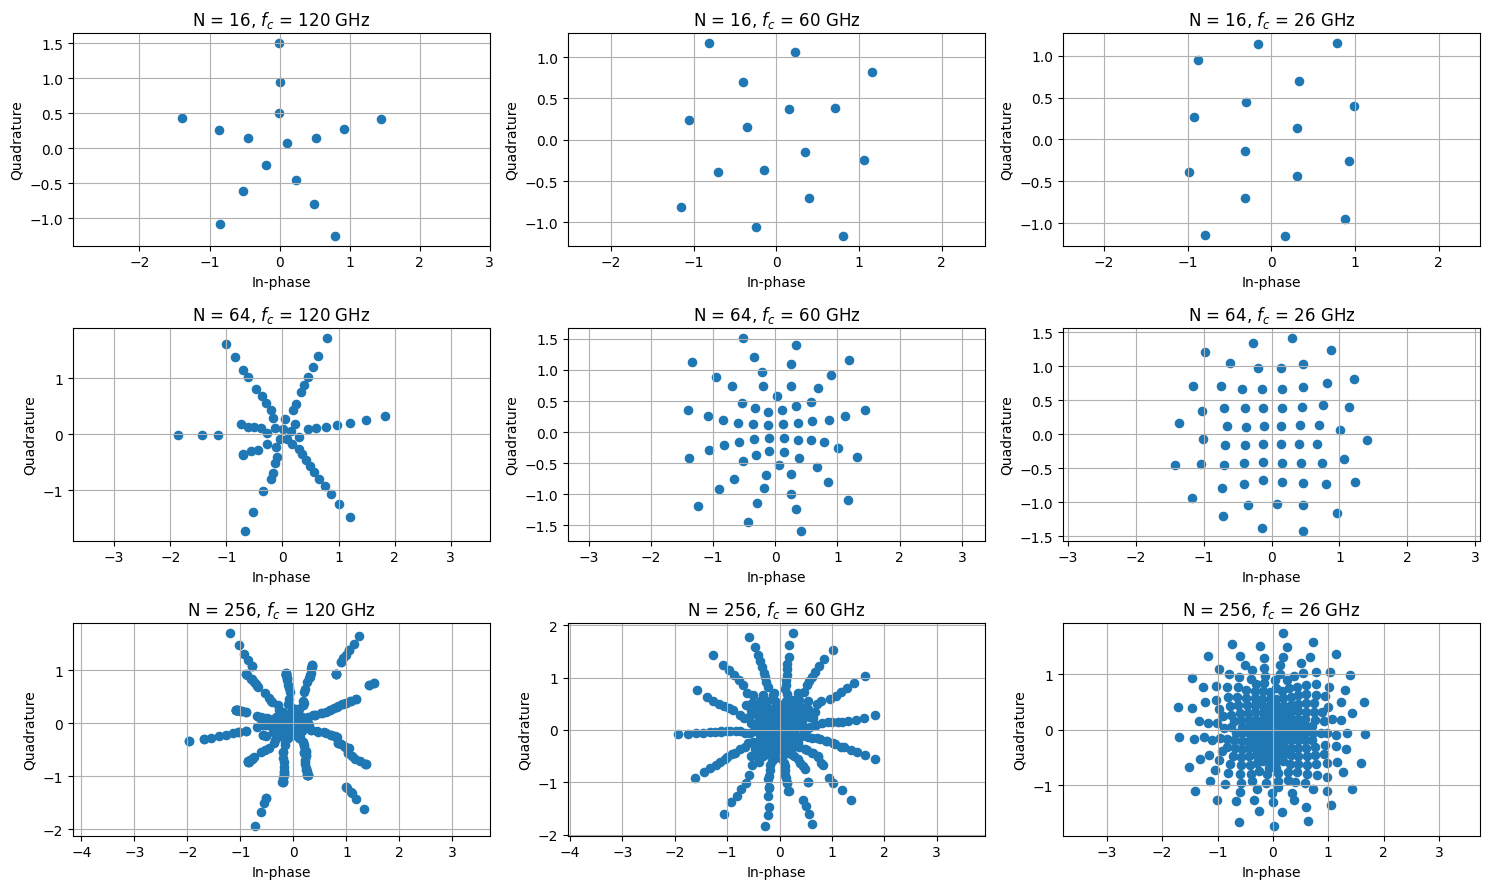

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    len(N_values),
    len(fc_values),
    figsize=(15, 9)
)

for row, N in enumerate(N_values):

    for col, fc in enumerate(fc_values):

        points = results[(N, fc)]

        ax = axes[row,col]

        ax.scatter(
            np.real(points),
            np.imag(points),
            s=35
        )

        ax.set_title(
            f"N = {N}, $f_c$ = {fc/1e9:.0f} GHz"
        )

        ax.set_xlabel("In-phase")
        ax.set_ylabel("Quadrature")

        ax.grid(True)
        ax.axis("equal")

plt.tight_layout()
plt.show()

In [10]:
np.savez(
    "learned_constellations.npz",
    **{
        f"N{N}_fc{int(fc/1e9)}GHz": points
        for (N, fc), points in results.items()
    }
)

In [ ]:
### loading data

In [13]:
data = np.load("learned_constellations.npz")

N_values = [16, 64]
fc_values = [26e9, 60e9, 120e9]

results_loaded = {}

for N in N_values:
    for fc in fc_values:

        key = f"N{N}_fc{int(fc/1e9)}GHz"

        results_loaded[(N, fc)] = data[key]

In [12]:
data.keys()

KeysView(NpzFile 'learned_constellations.npz' with keys: N16_fc120GHz, N16_fc60GHz, N16_fc26GHz, N64_fc120GHz, N64_fc60GHz...)